# Setup

In [13]:
import os
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels

In [26]:
recording_name = "balance1"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

filename_color_video = os.path.join("data", recording_name, recording_name + "_color.mp4")
filename_keypoints_2d = os.path.join("data", recording_name, recording_name + "_keypoints_2d.npy")
keypoints_2d = np.load(filename_keypoints_2d)

fps = 100
s_cut_1 = 700
q_cut_1 = 500

BASELINE_DURATION = 3 # seconds
q_cut_2 = q_cut_1 + len(stereo_keypoints) - s_cut_1 #TODO: this only works if the qualisys recoridng is longer than the stereo

baseline_end = BASELINE_DURATION * fps

qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

loaded data from: data\balance1\balance1_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\balance1\balance1_qualisys.npz with keys: ['labels', 'keypoints']


# Add COM keypoint

In [8]:
# OVERLAY 2D COORDS ON VIDEO
cap = cv2.VideoCapture(filename_color_video)
n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
frame_idx = 0
while frame_idx < n_frames-1:
    ret, frame = cap.read()
    w, h, _ = frame.shape
    if not ret or frame_idx >= len(keypoints_2d):
        break

    frame_raw = cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)

    for x, y in keypoints_2d[frame_idx]:
        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(frame_raw, (int(x), int(y)), 3, (0, 0, 255), -1)


    #COM: x% along mid_hip -> mid_shoulder
    # com_fraction = 0.15
    # mid_shoulder = keypoints_2d[frame_idx][stereo_labels.index("mid_shoulder")]
    # mid_hip = keypoints_2d[frame_idx][stereo_labels.index("mid_hip")]
    # com_x, com_y = mid_hip + com_fraction * (mid_shoulder - mid_hip)
    # if np.isfinite(com_x) and np.isfinite(com_y):
    #     cv2.circle(frame_raw, (int(com_x), int(com_y)), 6, (0, 255, 0), -1)


    cv2.putText(frame_raw, str(frame_idx), (40, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    cv2.putText(frame_raw, 'raw', (int(w/2), 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

    cv2.imshow("Raw & Filtered 2D", frame_raw)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == 27:
        break

    frame_idx += 1
    # time.sleep(0.075)
    time.sleep(0.03)

cap.release()
cv2.destroyAllWindows()

# COM movement

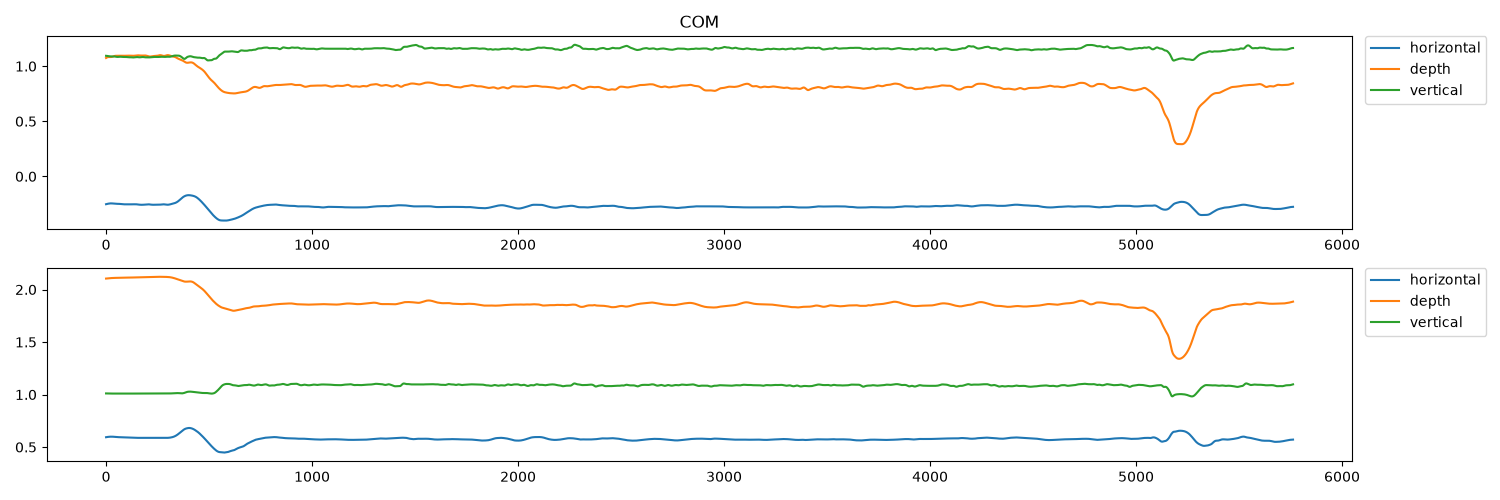

In [28]:


baseline_end = 200

plt.close('all')
fig, axs = plt.subplots(2,1, figsize=(15,5))
axs[0].set_title('COM')
axs[0].plot(stereo_keypoints[:,stereo_labels.index('center_of_mass'),:], label=['horizontal', 'depth', 'vertical'])
axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axs[1].plot(qualisys_keypoints[:,qualisys_labels.index('center_of_mass'),:], label=['horizontal', 'depth', 'vertical'])
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

plt.tight_layout()